<a href="https://colab.research.google.com/github/priyanga2004113-coder/Smart-City-Road-Accident-Analysis/blob/main/1_Smart_City_Road_Accident_Analytics_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================
# SMART CITY TRAFFIC ACCIDENT ANALYSIS
# Cleaning + Outlier Handling + EDA
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("Smart_City_Traffic_50K (1).csv")

# Display first 5 rows
df.head()

,Accident_ID,Severity,Start_Time,City,State,Start_Lat,Start_Lng,Weather_Condition,Visibility(mi),Precipitation(in),Crossing,Junction,Roundabout,Traffic_Signal,Sunrise_Sunset,Temperature(F)
0,A-1,3,2016-02-08 05:46:00,Dayton,OH,39.865147,-84.058723,Light Rain,10.0,0.02,False,False,False,False,Night,36.9
1,A-2,2,2016-02-08 06:07:59,Reynoldsburg,OH,39.928059,-82.831184,Light Rain,10.0,0.00,False,False,False,False,Night,37.9
2,A-3,2,2016-02-08 06:49:27,Williamsburg,OH,39.063148,-84.032608,Overcast,10.0,NaN,False,False,False,True,Night,36.0
3,A-4,3,2016-02-08 07:23:34,Dayton,OH,39.747753,-84.205582,Mostly Cloudy,9.0,NaN,False,False,False,False,Night,35.1
4,A-5,2,2016-02-08 07:39:07,Dayton,OH,39.627781,-84.188354,Mostly Cloudy,6.0,NaN,False,False,False,True,Day,36.0


In [ ]:
# Number of rows and columns
print("Rows and Columns:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

# Basic statistics
df.describe(include="all").T

Rows and Columns: (50000, 16)

Columns:
['Accident_ID', 'Severity', 'Start_Time', 'City', 'State', 'Start_Lat', 'Start_Lng', 'Weather_Condition', 'Visibility(mi)', 'Precipitation(in)', 'Crossing', 'Junction', 'Roundabout', 'Traffic_Signal', 'Sunrise_Sunset', 'Temperature(F)']

Data Types:
Accident_ID           object
Severity               int64
Start_Time            object
City                  object
State                 object
Start_Lat            float64
Start_Lng            float64
Weather_Condition     object
Visibility(mi)       float64
Precipitation(in)    float64
Crossing                bool
Junction                bool
Roundabout              bool
Traffic_Signal          bool
Sunrise_Sunset        object
Temperature(F)       float64
dtype: object


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Accident_ID,50000,50000,A-49984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Severity,50000.0,NaN,NaN,NaN,2.39678,0.49225,1.0,2.0,2.0,3.0,4.0
Start_Time,50000,49181,2016-04-10 08:59:26,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,50000,735,Sacramento,5223,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,50000,3,CA,49272,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Start_Lat,50000.0,NaN,NaN,NaN,37.396862,1.553001,32.544304,37.343647,37.776711,38.409191,41.428753
Start_Lng,50000.0,NaN,NaN,NaN,-120.736826,4.750326,-123.813927,-122.127098,-121.828537,-121.272102,-81.550728
Weather_Condition,49397,28,Clear,28116,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Visibility(mi),49474.0,NaN,NaN,NaN,9.384875,1.958316,0.1,10.0,10.0,10.0,80.0
Precipitation(in),3276.0,NaN,NaN,NaN,0.026529,0.050507,0.0,0.0,0.01,0.03,0.55


In [ ]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
# Remove duplicate rows
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (50000, 16)


In [ ]:
# Missing values
missing = df.isnull().sum()

print(missing)

Accident_ID              0
Severity                 0
Start_Time               0
City                     0
State                    0
Start_Lat                0
Start_Lng                0
Weather_Condition      603
Visibility(mi)         526
Precipitation(in)    46724
Crossing                 0
Junction                 0
Roundabout               0
Traffic_Signal           0
Sunrise_Sunset           0
Temperature(F)         456
dtype: int64


In [ ]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": missing_percent
})

missing_table.sort_values(
    by="Missing_Percentage",
    ascending=False
)

,Missing_Count,Missing_Percentage
Precipitation(in),46724,93.448
Weather_Condition,603,1.206
Visibility(mi),526,1.052
Temperature(F),456,0.912
City,0,0.000
Accident_ID,0,0.000
Start_Time,0,0.000
Severity,0,0.000
Start_Lng,0,0.000
Start_Lat,0,0.000


In [ ]:
# Fill categorical columns with mode
categorical_cols = [
    "City",
    "State",
    "Weather_Condition",
    "Sunrise_Sunset"
]

for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])


# Fill numerical columns with median
numerical_cols = [
    "Start_Lat",
    "Start_Lng",
    "Visibility(mi)",
    "Precipitation(in)",
    "Temperature(F)"
]

for col in numerical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

In [ ]:
print(df.isnull().sum())

Accident_ID          0
Severity             0
Start_Time           0
City                 0
State                0
Start_Lat            0
Start_Lng            0
Weather_Condition    0
Visibility(mi)       0
Precipitation(in)    0
Crossing             0
Junction             0
Roundabout           0
Traffic_Signal       0
Sunrise_Sunset       0
Temperature(F)       0
dtype: int64


In [ ]:
# Convert Start_Time to datetime
df["Start_Time"] = pd.to_datetime(
    df["Start_Time"],
    errors="coerce"
)

# Check datatype
print(df["Start_Time"].dtype)

datetime64[ns]


In [ ]:
# Extract hour
df["Hour"] = df["Start_Time"].dt.hour

# Extract day
df["Day"] = df["Start_Time"].dt.day

# Extract month number
df["Month"] = df["Start_Time"].dt.month

# Extract month name
df["Month_Name"] = df["Start_Time"].dt.month_name()

# Extract weekday
df["Weekday"] = df["Start_Time"].dt.day_name()

# Extract year
df["Year"] = df["Start_Time"].dt.year

In [ ]:
# Create time period
def time_period(hour):
    if 0 <= hour < 6:
        return "Night"
    elif 6 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 18:
        return "Afternoon"
    else:
        return "Evening"

df["Time_Period"] = df["Hour"].apply(time_period)

In [ ]:
severity_map = {
    1: "Low",
    2: "Moderate",
    3: "High",
    4: "Severe"
}

df["Severity_Level"] = df["Severity"].map(severity_map)

df[["Severity", "Severity_Level"]].head()

,Severity,Severity_Level
0,3,High
1,2,Moderate
2,2,Moderate
3,3,High
4,2,Moderate


In [ ]:
print("Severity values:")
print(df["Severity"].value_counts().sort_index())

Severity values:
Severity
1       58
2    30061
3    19865
4       16
Name: count, dtype: int64


In [ ]:
print("Visibility <= 0:",
      (df["Visibility(mi)"] <= 0).sum())

Visibility <= 0: 0


In [ ]:
print("Negative precipitation:",
      (df["Precipitation(in)"] < 0).sum())

Negative precipitation: 0


In [ ]:
print("Temperature statistics:")
print(df["Temperature(F)"].describe())

Temperature statistics:
count    50000.000000
mean        64.970076
std         13.140574
min          3.900000
25%         56.300000
50%         64.400000
75%         73.400000
max        113.000000
Name: Temperature(F), dtype: float64


In [ ]:
# Function for IQR outlier capping

def cap_outliers_iqr(data, column):

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    data[column] = data[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

    return lower_bound, upper_bound

In [ ]:
outlier_cols = [
    "Visibility(mi)",
    "Precipitation(in)"
]
for col in outlier_cols:
    lower, upper = cap_outliers_iqr(df, col)

    print(
        f"{col}: Lower = {lower:.2f}, "
        f"Upper = {upper:.2f}"
    )

Visibility(mi): Lower = 10.00, Upper = 10.00
Precipitation(in): Lower = 0.01, Upper = 0.01


In [ ]:
def road_feature(row):

    if row["Junction"]:
        return "Junction"

    elif row["Traffic_Signal"]:
        return "Traffic Signal"

    elif row["Roundabout"]:
        return "Roundabout"

    elif row["Crossing"]:
        return "Crossing"

    else:
        return "Other"

df["Road_Feature"] = df.apply(
    road_feature,
    axis=1
)

In [ ]:
df["Road_Feature"].value_counts()

,count
Road_Feature,
Other,36499
Junction,6695
Traffic Signal,5036
Crossing,1769
Roundabout,1


In [ ]:
def weather_category(weather):

    weather = str(weather).lower()

    if "rain" in weather:
        return "Rain"

    elif "snow" in weather:
        return "Snow"

    elif "fog" in weather or "haze" in weather or "mist" in weather:
        return "Fog/Mist"

    elif "storm" in weather or "thunder" in weather:
        return "Storm"

    elif "clear" in weather:
        return "Clear"

    elif "cloud" in weather or "overcast" in weather:
        return "Cloudy"

    else:
        return "Other"

df["Weather_Category"] = df["Weather_Condition"].apply(
    weather_category
)

df["Weather_Category"].value_counts()

,count
Weather_Category,
Clear,28719
Cloudy,17829
Rain,2252
Fog/Mist,864
Other,218
Snow,118


In [ ]:
def visibility_category(value):

    if value < 2:
        return "Very Low"

    elif value < 5:
        return "Low"

    elif value < 10:
        return "Moderate"

    else:
        return "Good"

df["Visibility_Category"] = df["Visibility(mi)"].apply(
    visibility_category
)

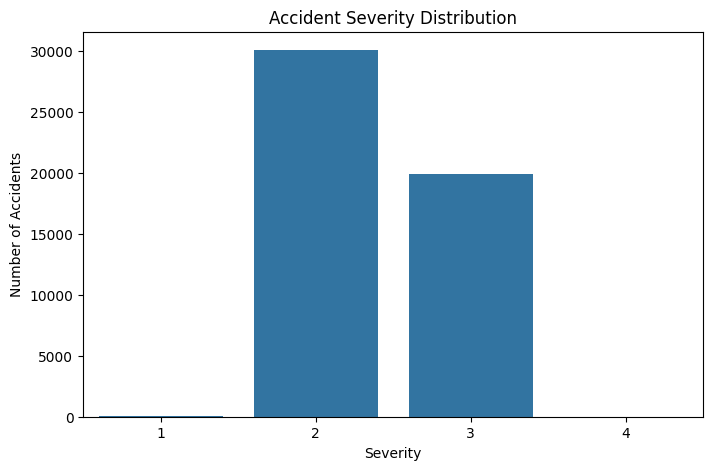

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Severity"
)

plt.title("Accident Severity Distribution")
plt.xlabel("Severity")
plt.ylabel("Number of Accidents")

plt.show()

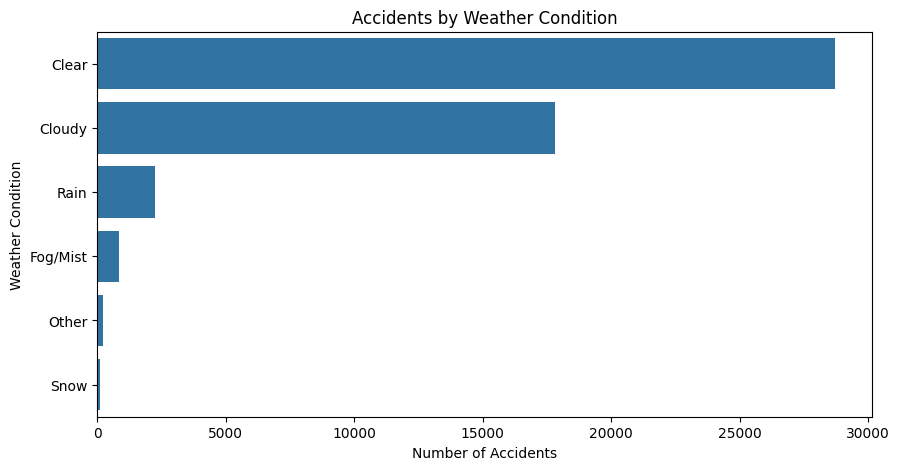

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    y="Weather_Category",
    order=df["Weather_Category"].value_counts().index
)

plt.title("Accidents by Weather Condition")
plt.xlabel("Number of Accidents")
plt.ylabel("Weather Condition")

plt.show()

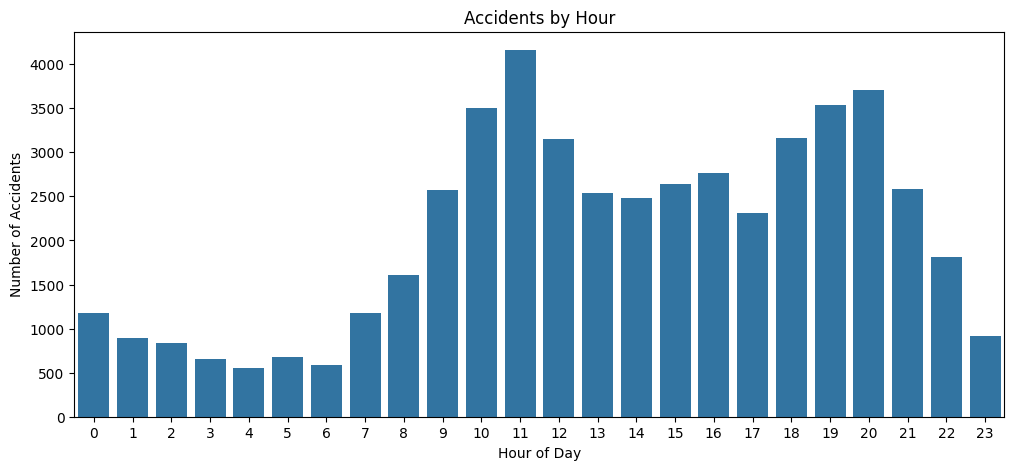

In [ ]:
plt.figure(figsize=(12,5))

sns.countplot(
    data=df,
    x="Hour"
)

plt.title("Accidents by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Accidents")

plt.show()

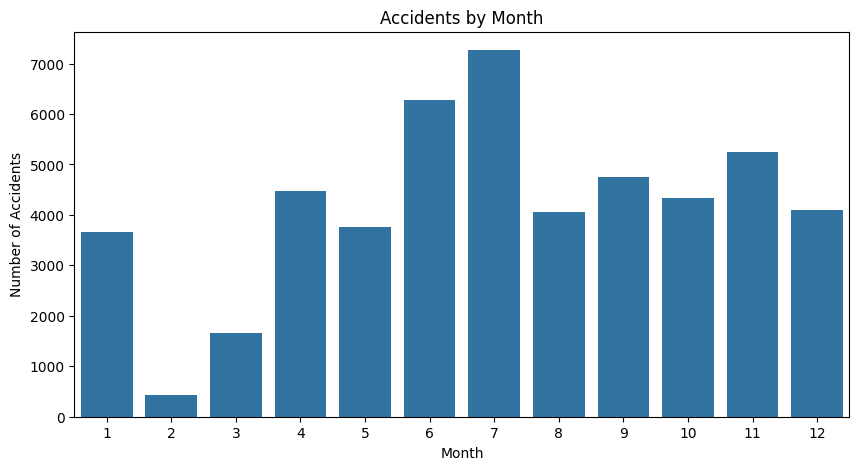

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="Month"
)

plt.title("Accidents by Month")
plt.xlabel("Month")
plt.ylabel("Number of Accidents")

plt.show()

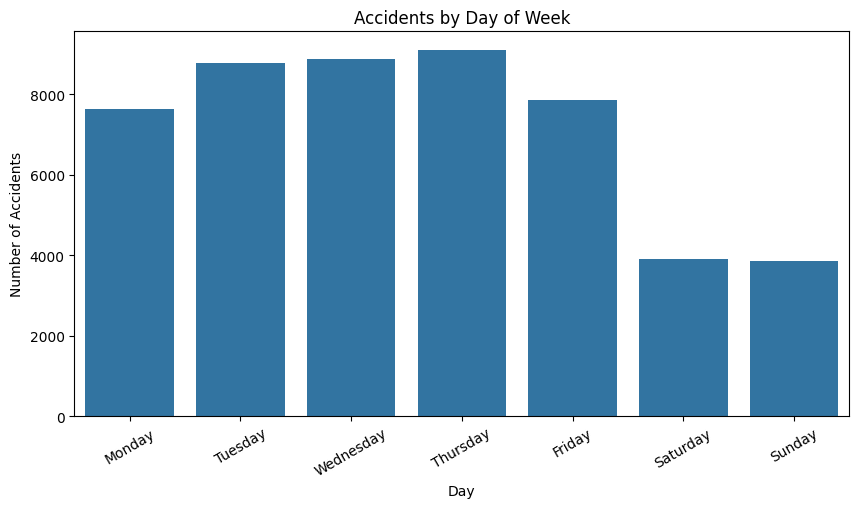

In [ ]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="Weekday",
    order=weekday_order
)

plt.title("Accidents by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Accidents")

plt.xticks(rotation=30)

plt.show()

In [ ]:
weather_severity = pd.crosstab(
    df["Weather_Category"],
    df["Severity"]
)

weather_severity

Severity,1,2,3,4
Weather_Category,,,,
Clear,34,17665,11013,7
Cloudy,20,10384,7418,7
Fog/Mist,0,544,319,1
Other,0,145,73,0
Rain,4,1259,988,1
Snow,0,64,54,0


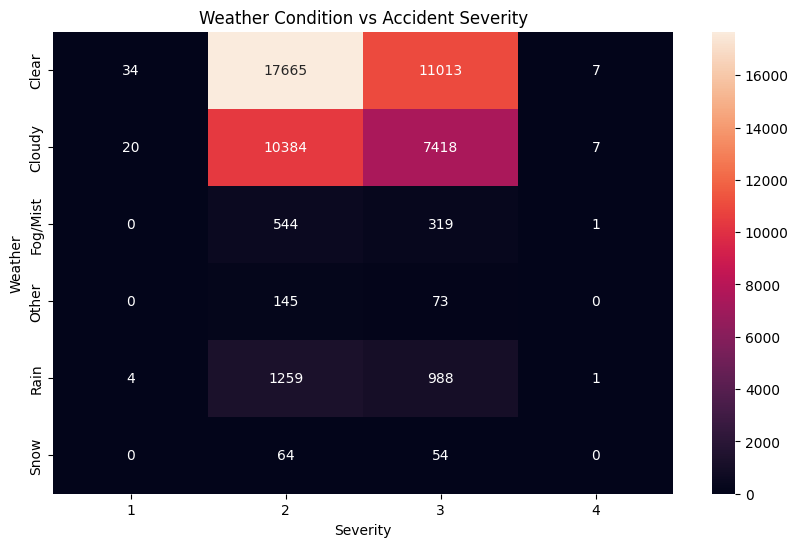

In [ ]:
plt.figure(figsize=(10,6))

sns.heatmap(
    weather_severity,
    annot=True,
    fmt="d"
)

plt.title("Weather Condition vs Accident Severity")
plt.xlabel("Severity")
plt.ylabel("Weather")

plt.show()

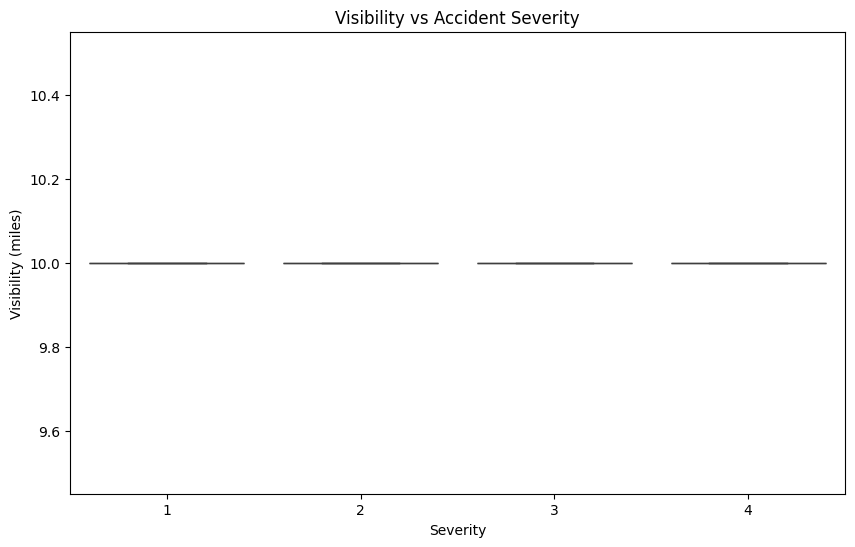

In [ ]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x="Severity",
    y="Visibility(mi)"
)

plt.title("Visibility vs Accident Severity")
plt.xlabel("Severity")
plt.ylabel("Visibility (miles)")

plt.show()

In [ ]:
# Check temperature range
print("Minimum:", df["Temperature(F)"].min())
print("Maximum:", df["Temperature(F)"].max())

# Check extreme values
print(
    df[
        (df["Temperature(F)"] < -100) |
        (df["Temperature(F)"] > 150)
    ][["Temperature(F)"]]
)

Minimum: 30.649999999999984
Maximum: 99.05000000000001
Empty DataFrame
Columns: [Temperature(F)]
Index: []


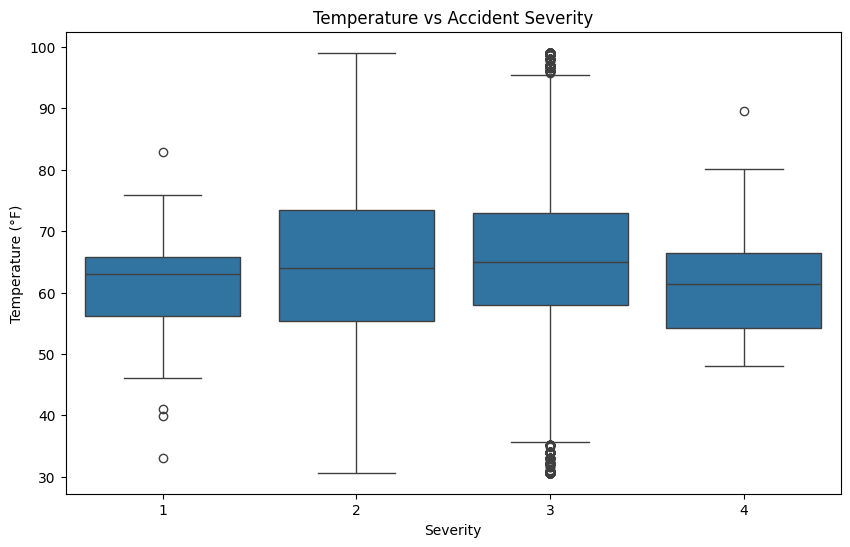

In [ ]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x="Severity",
    y="Temperature(F)"
)

plt.title("Temperature vs Accident Severity")
plt.xlabel("Severity")
plt.ylabel("Temperature (°F)")

plt.show()

In [ ]:
road_severity = pd.crosstab(
    df["Road_Feature"],
    df["Severity"]
)

road_severity

Severity,1,2,3,4
Road_Feature,,,,
Crossing,11,1560,198,0
Junction,0,2913,3779,3
Other,36,21210,15241,12
Roundabout,0,1,0,0
Traffic Signal,11,4377,647,1


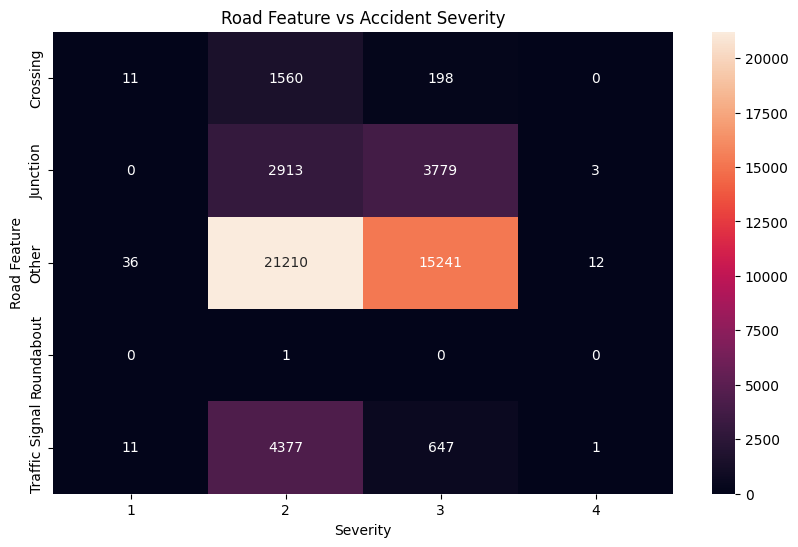

In [ ]:
plt.figure(figsize=(10,6))

sns.heatmap(
    road_severity,
    annot=True,
    fmt="d"
)

plt.title("Road Feature vs Accident Severity")
plt.xlabel("Severity")
plt.ylabel("Road Feature")

plt.show()

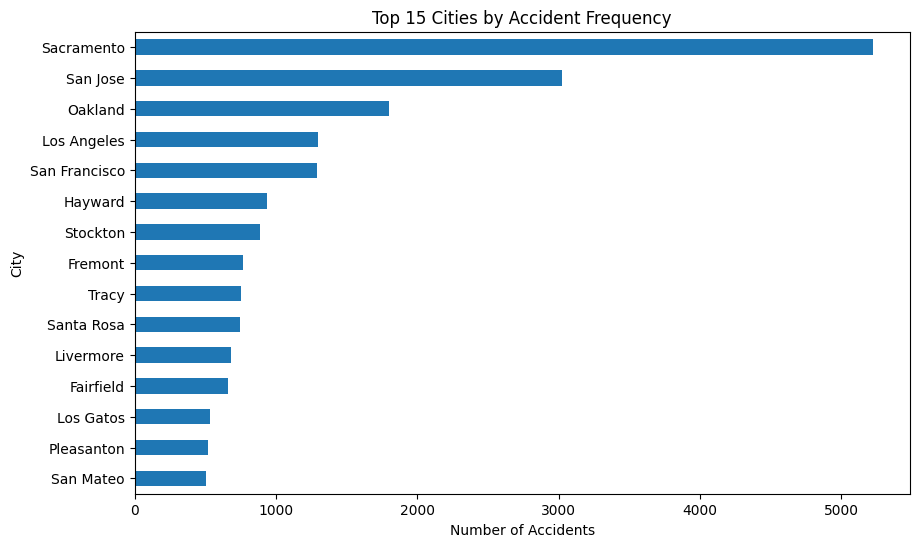

In [ ]:
city_accidents = (
    df["City"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(10,6))

city_accidents.sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Cities by Accident Frequency")
plt.xlabel("Number of Accidents")
plt.ylabel("City")

plt.show()

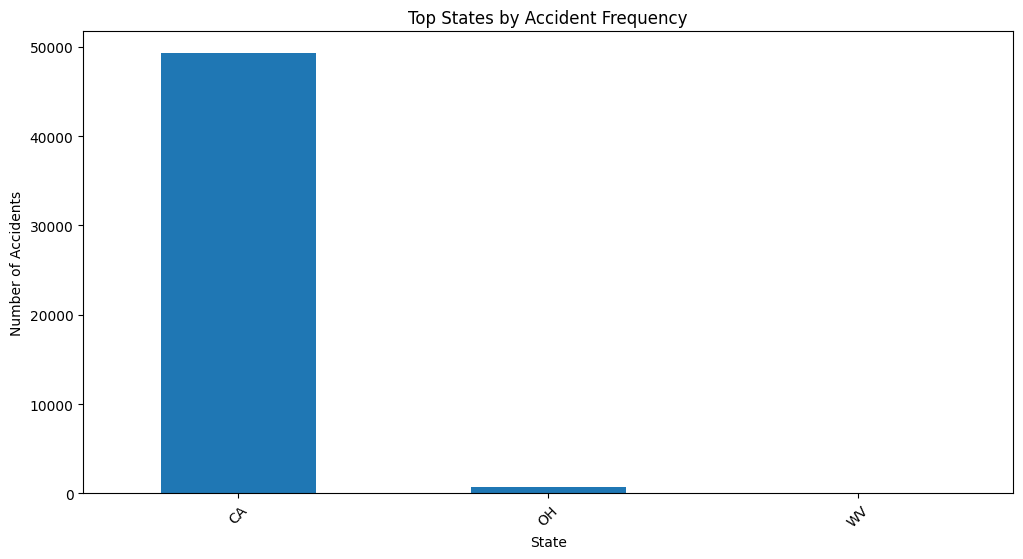

In [ ]:
state_accidents = df["State"].value_counts()

plt.figure(figsize=(12,6))

state_accidents.head(15).plot(
    kind="bar"
)

plt.title("Top States by Accident Frequency")
plt.xlabel("State")
plt.ylabel("Number of Accidents")

plt.xticks(rotation=45)

plt.show()

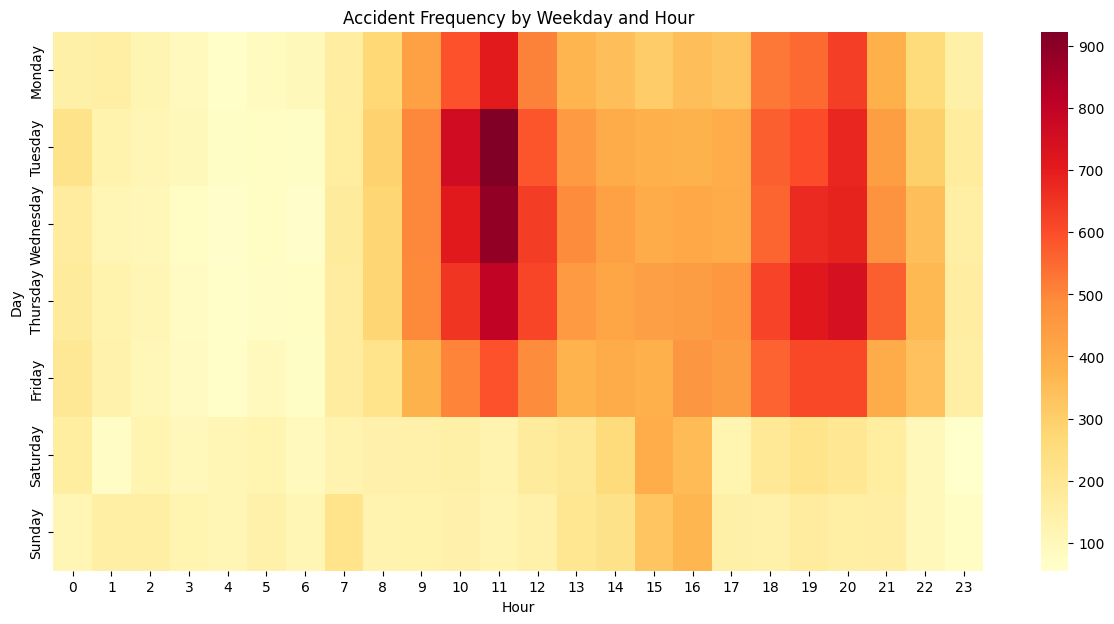

In [ ]:
hour_weekday = pd.pivot_table(
    df,
    values="Accident_ID",
    index="Weekday",
    columns="Hour",
    aggfunc="count"
)

hour_weekday = hour_weekday.reindex(weekday_order)

plt.figure(figsize=(15,7))

sns.heatmap(
    hour_weekday,
    cmap="YlOrRd"
)

plt.title("Accident Frequency by Weekday and Hour")
plt.xlabel("Hour")
plt.ylabel("Day")

plt.show()

In [ ]:
road_weather = pd.crosstab(
    df["Road_Feature"],
    [df["Weather_Category"], df["Severity"]]
)

road_weather

Weather_Category Clear                 Cloudy                Fog/Mist          \
Severity             1      2     3  4      1     2     3  4        2    3  4   
Road_Feature                                                                    
Crossing             8    977   109  0      3   504    71  0       22    3  0   
Junction             0   1529  2053  1      0  1162  1458  1       45   50  1   
Other               22  12425  8538  5     11  7339  5604  6      403  256  0   
Roundabout           0      0     0  0      0     1     0  0        0    0  0   
Traffic Signal       4   2734   313  1      6  1378   285  0       74   10  0   

Weather_Category Other     Rain              Snow      
Severity             2   3    1    2    3  4    2   3  
Road_Feature                                           
Crossing             1   2    0   54   13  0    2   0  
Junction             4   5    0  172  200  0    1  13  
Other              118  65    3  876  738  1   49  40  
Roundabout           0   0    0    0    0  0    0   0  
Traffic Signal      22   1    1  157   37  0   12   1

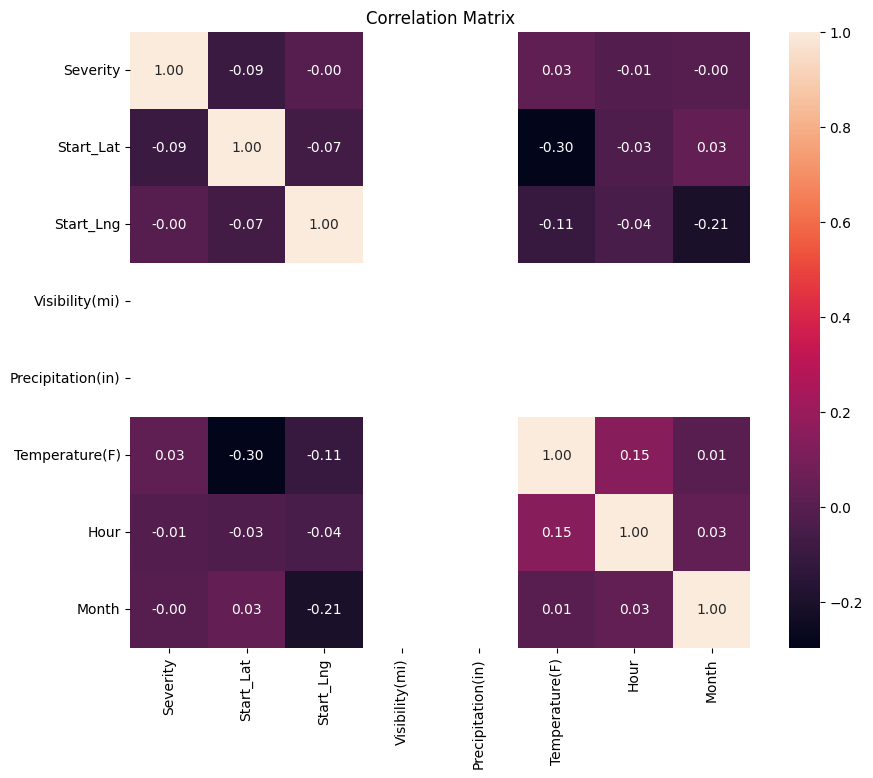

In [ ]:
numeric_cols = [
    "Severity",
    "Start_Lat",
    "Start_Lng",
    "Visibility(mi)",
    "Precipitation(in)",
    "Temperature(F)",
    "Hour",
    "Month"
]

correlation = df[numeric_cols].corr()

plt.figure(figsize=(10,8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

In [ ]:
print("Final Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Final Shape: (50000, 27)

Missing Values:
Accident_ID            0
Severity               0
Start_Time             0
City                   0
State                  0
Start_Lat              0
Start_Lng              0
Weather_Condition      0
Visibility(mi)         0
Precipitation(in)      0
Crossing               0
Junction               0
Roundabout             0
Traffic_Signal         0
Sunrise_Sunset         0
Temperature(F)         0
Hour                   0
Day                    0
Month                  0
Month_Name             0
Weekday                0
Year                   0
Time_Period            0
Severity_Level         0
Road_Feature           0
Weather_Category       0
Visibility_Category    0
dtype: int64

Duplicate Rows:
0

Data Types:
Accident_ID                    object
Severity                        int64
Start_Time             datetime64[ns]
City                           object
State                          object
Start_Lat                     float64
Start_Lng 

In [ ]:
# Save cleaned dataset
output_path = "Smart_City_Traffic_Cleaned.csv (1)"

df.to_csv(
    output_path,
    index=False
)

print("Cleaned dataset saved successfully!")
print(output_path)

Cleaned dataset saved successfully!
Smart_City_Traffic_Cleaned.csv (1)


In [ ]:
import pandas as pd
import numpy as np

# Load original dataset
df = pd.read_csv("Smart_City_Traffic_50K (1).csv")

# --------------------------------
# 1. Remove duplicate rows
# --------------------------------
df = df.drop_duplicates()

# --------------------------------
# 2. Convert date column
# --------------------------------
df["Start_Time"] = pd.to_datetime(
    df["Start_Time"],
    errors="coerce"
)

# --------------------------------
# 3. Fill categorical missing values
# --------------------------------
categorical_cols = [
    "Weather_Condition"
]

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# --------------------------------
# 4. Fill numerical missing values
# --------------------------------
numerical_cols = [
    "Start_Lat",
    "Start_Lng",
    "Visibility(mi)",
    "Precipitation(in)",
    "Temperature(F)"
]

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# --------------------------------
# 5. Create time features
# --------------------------------
df["Hour"] = df["Start_Time"].dt.hour
df["Day"] = df["Start_Time"].dt.day
df["Month"] = df["Start_Time"].dt.month
df["Month_Name"] = df["Start_Time"].dt.month_name()
df["Weekday"] = df["Start_Time"].dt.day_name()
df["Year"] = df["Start_Time"].dt.year

# --------------------------------
# 6. Time Period
# --------------------------------
def time_period(hour):
    if hour < 6:
        return "Night"
    elif hour < 12:
        return "Morning"
    elif hour < 18:
        return "Afternoon"
    else:
        return "Evening"

df["Time_Period"] = df["Hour"].apply(time_period)

# --------------------------------
# 7. Severity category
# --------------------------------
severity_map = {
    1: "Low",
    2: "Moderate",
    3: "High",
    4: "Severe"
}

df["Severity_Level"] = df["Severity"].map(severity_map)

# --------------------------------
# 8. Road feature
# --------------------------------
def road_feature(row):
    if row["Junction"]:
        return "Junction"
    elif row["Traffic_Signal"]:
        return "Traffic Signal"
    elif row["Roundabout"]:
        return "Roundabout"
    elif row["Crossing"]:
        return "Crossing"
    else:
        return "Other"

df["Road_Feature"] = df.apply(road_feature, axis=1)

# --------------------------------
# 9. Weather category
# --------------------------------
def weather_category(weather):
    weather = str(weather).lower()

    if "rain" in weather:
        return "Rain"
    elif "snow" in weather:
        return "Snow"
    elif "fog" in weather or "haze" in weather or "mist" in weather:
        return "Fog/Mist"
    elif "storm" in weather or "thunder" in weather:
        return "Storm"
    elif "clear" in weather:
        return "Clear"
    elif "cloud" in weather or "overcast" in weather:
        return "Cloudy"
    else:
        return "Other"

df["Weather_Category"] = df["Weather_Condition"].apply(
    weather_category
)

# --------------------------------
# 10. Visibility category
# --------------------------------
def visibility_category(value):
    if value < 2:
        return "Very Low"
    elif value < 5:
        return "Low"
    elif value < 10:
        return "Moderate"
    else:
        return "Good"

df["Visibility_Category"] = df["Visibility(mi)"].apply(
    visibility_category
)

# --------------------------------
# 11. Final validation
# --------------------------------
print("Shape:", df.shape)
print("Duplicates:", df.duplicated().sum())
print("Missing values:")
print(df.isnull().sum())

# --------------------------------
# 12. Save cleaned dataset
# --------------------------------
df.to_csv(
    "Smart_City_Traffic_Cleaned_Final.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Shape: (50000, 27)
Duplicates: 0
Missing values:
Accident_ID            0
Severity               0
Start_Time             0
City                   0
State                  0
Start_Lat              0
Start_Lng              0
Weather_Condition      0
Visibility(mi)         0
Precipitation(in)      0
Crossing               0
Junction               0
Roundabout             0
Traffic_Signal         0
Sunrise_Sunset         0
Temperature(F)         0
Hour                   0
Day                    0
Month                  0
Month_Name             0
Weekday                0
Year                   0
Time_Period            0
Severity_Level         0
Road_Feature           0
Weather_Category       0
Visibility_Category    0
dtype: int64
Cleaned dataset saved successfully!


In [ ]:
# Numerical columns for outlier detection
outlier_cols = [
    "Visibility(mi)",
    "Precipitation(in)",
    "Temperature(F)"
]

for col in outlier_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print("\n", col)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Number of outliers:", len(outliers))


 Visibility(mi)
Lower limit: 10.0
Upper limit: 10.0
Number of outliers: 8229

 Precipitation(in)
Lower limit: 0.01
Upper limit: 0.01
Number of outliers: 2699

 Temperature(F)
Lower limit: 30.649999999999984
Upper limit: 99.05000000000001
Number of outliers: 460


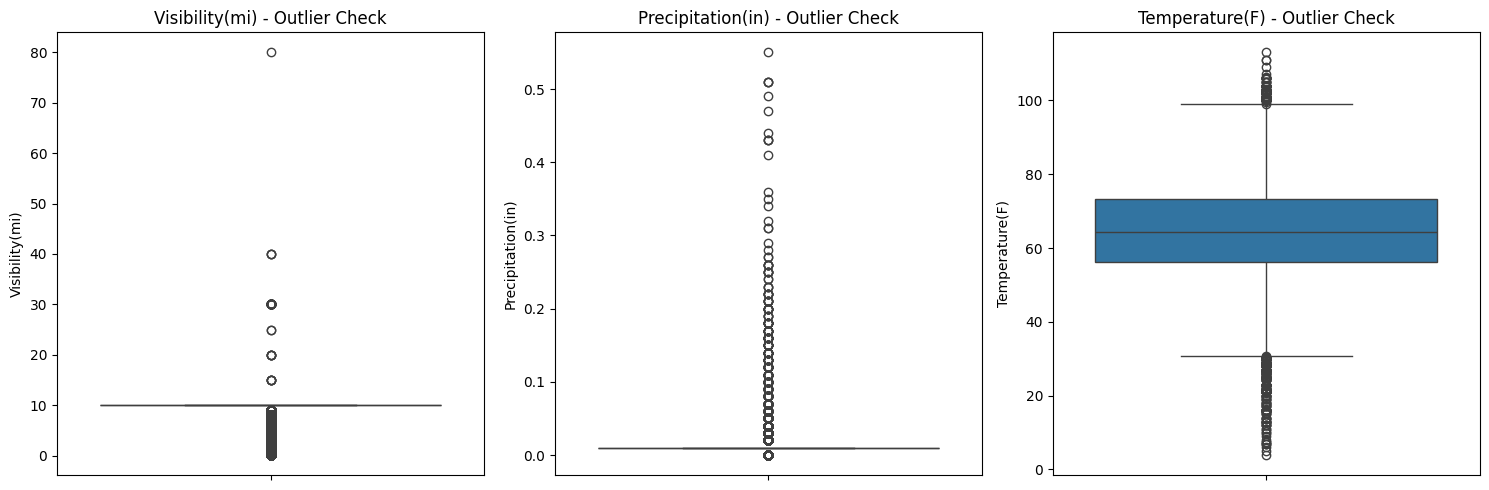

In [ ]:
plt.figure(figsize=(15, 5))

for i, col in enumerate(outlier_cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f"{col} - Outlier Check")

plt.tight_layout()
plt.show()

In [ ]:
df["Temperature(F)"].sort_values().head(10)
df["Temperature(F)"].sort_values().tail(10)

,Temperature(F)
4456,106.0
44099,106.0
43623,106.0
47468,106.0
44462,106.3
45103,107.1
44046,109.0
49206,111.0
49140,111.0
44982,113.0


In [ ]:
df["Visibility(mi)"].sort_values().tail(10)
df["Precipitation(in)"].sort_values().tail(10)

,Precipitation(in)
24880,0.43
24878,0.43
24870,0.43
10677,0.44
24879,0.47
7261,0.49
11585,0.51
11584,0.51
11581,0.51
24824,0.55
